In [1]:
RERUN = False          # DNA_RERUN=1 in the environment turns the GPU rerun cells on
from _common import *
from _dna_helpers import *
import matplotlib.pyplot as plt

RERUN = rerun_flag(RERUN)
P = paper()
LENGTHS = [50, 100, 200, 400]
REWARDS = ["gc", "motif", "conjunction"]

# 05 · Monte Carlo scaling, posterior diversity and dMFM-vs-GLASS error (Fig 5, Tables 14, 15, 17, 18)

Paper §3.3 and App. F.2, F.3, F.5, F.6.

| Paper item | Source run (dirichlet-flow-matching/workdir) | Status |
|---|---|---|
| Fig 5, Tables 14–15 | `rebuttal_gradient_accuracy_{gc_pairmetrics,motif,conjunction}` (jobs 35338216, 35258314, 35258315), rescored 2026-08-02 with `rescore_gradient_pairs_scale_free.py` | reproduced exactly |
| Table 17 | `parent_posterior_diversity_mapselected_flowmap1_glass100_20260726` (job 35378081) | reproduced exactly |
| Table 18 | `rebuttal_dmfm4_glass128_mae_precision_20260727` (job array 35642548), rescored with `rescore_gradient_pairs_mae.py` | numbers reproduced exactly; **text says t = 0.3, runs used t_eval = 0.5** (known) |

## Tables 14–15 — scale-free finite-MC gradient accuracy

For each length: 32 conditioning states x_t at t_eval = 0.5, 8 independent noise pools per state,
N ∈ {1, …, 256} GLASS posterior samples per estimate, reference = independent GLASS estimate with 2,048 samples.

**Correction to the paper's description (l. 1577 and the Fig 5 caption area).** The conditioning states are *not*
noised held-out sequences: `ablate_glass_gradient_mc.make_probe_states` draws `seeded_randn` (seed
20260726 + 1,000,000 + L) and integrates the **base flow** to t = 0.5 with 32 NFE — the script never opens the data
or the split files, and the stored `metadata.json` has no `probe_split` key. They are model samples. (The
held-out-state variant, `make_heldout_probe_states`, exists only in `ablate_dmfm_one_step_gradient_mc`, i.e. the
Table 18 runs, which do use the `test` split.)

**Second discrepancy (for the authors).** Both sides of this comparison are the *same* GLASS estimator on the same
base DFM, differing only in the number of terminal-noise samples (N vs 2,048): `ablate_glass_gradient_mc` has no
dMFM code path at all. So the published Fig 5 / Tables 14–15 measure GLASS Monte Carlo error, not dMFM error, which
contradicts the Fig 5 caption and App. F.2. The authors' decision is to rerun with real dMFM gradients; that rerun
(and a side-by-side with these published numbers) is the "dMFM rerun" section after Fig 5 below. Pooled relative ℓ1 (eq. 46) = Σ_{s,r} ‖ĝ − g⋆‖₁ / (R · Σ_s ‖g⋆‖₁); cosine (eq. 47) = mean over states
of the per-state mean (over the 8 pools) cosine.

`scale_free_mc/scale_free_per_state_sums.csv` holds, per (reward, length, state, N), the ℓ1 error summed over the 8
pools, the reference ℓ1 norm and the pool-mean cosine; these were computed in float64 from the original
`gradient_pairs.pt` tensors (1.9–15 MB each, not copied), so the pooled metrics below are an exact re-aggregation.

In [2]:
sf = load_csv("dna/scale_free_mc/scale_free_per_state_sums.csv")
agg = sf.groupby(["reward", "length", "mc"]).agg(err=("abs_err_l1_sum_over_repeats", "sum"), ref=("ref_l1", "sum"),
                                                 cosine=("cosine_mean_over_repeats", "mean"), n_states=("state", "size"),
                                                 n_repeats=("n_repeats", "first")).reset_index()
agg["rel_l1"] = agg.err / (agg.ref * agg.n_repeats)
p15 = P["table15_scale_free_full"]
rows = []
for r in REWARDS:
    for mc, byL in p15[r].items():
        for L, (rel, cos) in byL.items():
            o = agg[(agg.reward == r) & (agg.length == int(L)) & (agg.mc == int(mc))].iloc[0]
            rows += [dict(item=f"{r} N={mc} L{L} rel l1", paper=rel, ours=o.rel_l1, dec=2),
                     dict(item=f"{r} N={mc} L{L} cosine", paper=cos, ours=o.cosine, dec=2)]
t15 = show(cmp(rows))
t15[t15.status != "match"] if (t15.status != "match").any() else print("all 216 Table 15 entries match")

status counts: {'match': 216}
all 216 Table 15 entries match


In [3]:
# the same values as a paper-style table ("rel / cos")
wide = agg.assign(cell=lambda d: d.rel_l1.map(lambda v: f"{v:.2f}") + " / " + d.cosine.map(lambda v: f"{v:.2f}")) \
          .pivot_table(index=["reward", "mc"], columns="length", values="cell", aggfunc="first").reindex(REWARDS, level=0)
wide

length                   50           100          200          400
reward      mc                                                     
gc          1    3.41 / 0.14  3.51 / 0.15  2.71 / 0.16  2.95 / 0.14
            2    3.46 / 0.16  2.63 / 0.19  2.17 / 0.19  2.45 / 0.17
            4    2.19 / 0.19  2.02 / 0.21  1.65 / 0.24  1.80 / 0.22
            8    1.92 / 0.24  1.67 / 0.27  1.40 / 0.32  1.48 / 0.26
            16   1.62 / 0.32  1.42 / 0.36  1.11 / 0.44  1.27 / 0.34
            32   1.30 / 0.43  1.13 / 0.48  0.94 / 0.57  1.00 / 0.45
            64   1.06 / 0.54  0.92 / 0.58  0.76 / 0.67  0.82 / 0.57
            128  0.82 / 0.64  0.72 / 0.69  0.58 / 0.77  0.66 / 0.67
            256  0.63 / 0.74  0.55 / 0.78  0.45 / 0.85  0.51 / 0.76
motif       1    3.18 / 0.14  4.64 / 0.13  4.53 / 0.15  3.61 / 0.15
            2    3.16 / 0.17  3.44 / 0.15  3.14 / 0.18  2.66 / 0.18
            4    2.67 / 0.20  2.79 / 0.19  2.52 / 0.21  2.30 / 0.22
            8    2.07 / 0.24  1.92 / 0.26  1.94 / 0.26  1.47 / 0.28
            16   1.93 / 0.30  1.53 / 0.32  1.56 / 0.33  1.25 / 0.36
            32   1.47 / 0.37  1.30 / 0.37  1.33 / 0.43  1.02 / 0.47
            64   1.23 / 0.47  1.06 / 0.48  1.06 / 0.52  0.88 / 0.55
            128  1.05 / 0.57  0.92 / 0.57  0.86 / 0.61  0.71 / 0.66
            256  0.84 / 0.66  0.75 / 0.67  0.72 / 0.72  0.56 / 0.76
conjunction 1    4.18 / 0.10  5.51 / 0.10  5.08 / 0.11  4.56 / 0.10
            2    4.03 / 0.13  4.53 / 0.12  3.62 / 0.12  3.32 / 0.12
            4    3.33 / 0.14  3.14 / 0.14  2.74 / 0.15  2.79 / 0.16
            8    2.55 / 0.20  2.30 / 0.21  2.19 / 0.20  1.93 / 0.18
            16   2.22 / 0.22  1.90 / 0.24  1.79 / 0.26  1.59 / 0.25
            32   1.72 / 0.29  1.66 / 0.31  1.49 / 0.35  1.34 / 0.32
            64   1.49 / 0.38  1.34 / 0.41  1.24 / 0.44  1.16 / 0.41
            128  1.23 / 0.49  1.15 / 0.50  0.98 / 0.54  0.93 / 0.52
            256  1.01 / 0.58  0.92 / 0.61  0.81 / 0.65  0.76 / 0.63

In [4]:
# Table 14 is the N in {8, 128} subset of Table 15
p14 = P["table14_scale_free_subset"]
rows = []
for r in REWARDS:
    for mc, byL in p14[r].items():
        for L, (rel, cos) in byL.items():
            o = agg[(agg.reward == r) & (agg.length == int(L)) & (agg.mc == int(mc))].iloc[0]
            rows += [dict(item=f"{r} N={mc} L{L} rel l1", paper=rel, ours=o.rel_l1, dec=2), dict(item=f"{r} N={mc} L{L} cosine", paper=cos, ours=o.cosine, dec=2)]
show(cmp(rows)).status.value_counts()

status counts: {'match': 48}


status
match    48
Name: count, dtype: int64

Consistency with the summaries written by the original rescoring (`gradient_scale_free_summary_all_lengths.csv`,
float32 sums): max absolute difference of our float64 re-aggregation.

In [5]:
diffs = []
for r in REWARDS:
    s = load_csv(f"dna/scale_free_mc/{r}/gradient_scale_free_summary_all_lengths.csv")
    m = s.merge(agg[agg.reward == r], on=["length", "mc"])
    diffs.append({"reward": r, "max|rel_l1 diff|": (m.global_relative_l1 - m.rel_l1).abs().max(), "max|cos diff|": (m.mean_cosine - m.cosine).abs().max()})
pd.DataFrame(diffs)

,reward,max|rel_l1 diff|,max|cos diff|
0,gc,6.350655e-07,6.459062e-08
1,motif,5.516562e-07,4.759375e-08
2,conjunction,8.374674e-07,4.503125e-08


## §3.3 text: "At N = 8, relative errors are 1.40–2.55 and cosine similarities are 0.18–0.32."

In [6]:
n8 = agg[agg.mc == 8]
t = P["sec3_3_text"]
show(cmp([dict(item="N=8 min rel l1", paper=t["n8_relative_l1_range"][0], ours=n8.rel_l1.min(), dec=2),
          dict(item="N=8 max rel l1", paper=t["n8_relative_l1_range"][1], ours=n8.rel_l1.max(), dec=2),
          dict(item="N=8 min cosine", paper=t["n8_cosine_range"][0], ours=n8.cosine.min(), dec=2),
          dict(item="N=8 max cosine", paper=t["n8_cosine_range"][1], ours=n8.cosine.max(), dec=2),
          dict(item="states per length", paper=t["n_states"], ours=int(agg.n_states.min()), atol=0),
          dict(item="noise pools per state", paper=t["n_pools"], ours=int(agg.n_repeats.min()), atol=0),
          dict(item="reference MC (GLASS)", paper=t["reference_mc"], ours=load_json("dna/scale_free_mc/gc/run_metadata.json")["args"]["reference_mc"], atol=0)]))

status counts: {'match': 7}


,item,paper,ours,status,tol,tol_src,note
0,N=8 min rel l1,1.40,1.399815,match,0.005,atol,
1,N=8 max rel l1,2.55,2.550106,match,0.005,atol,
2,N=8 min cosine,0.18,0.184770,match,0.005,atol,
3,N=8 max cosine,0.32,0.319500,match,0.005,atol,
4,states per length,32.00,32.000000,match,0.000,atol,
5,noise pools per state,8.00,8.000000,match,0.000,atol,
6,reference MC (GLASS),2048.00,2048.000000,match,0.000,atol,


## Fig 5 — rebuilt from the re-aggregated values
The producing plot script for the paper's exact styling was not found (the figures in
`workdir/rebuttal_gradient_accuracy_figures/` are an older "required MC" plot); the layout, colors and markers
below follow the paper figure.

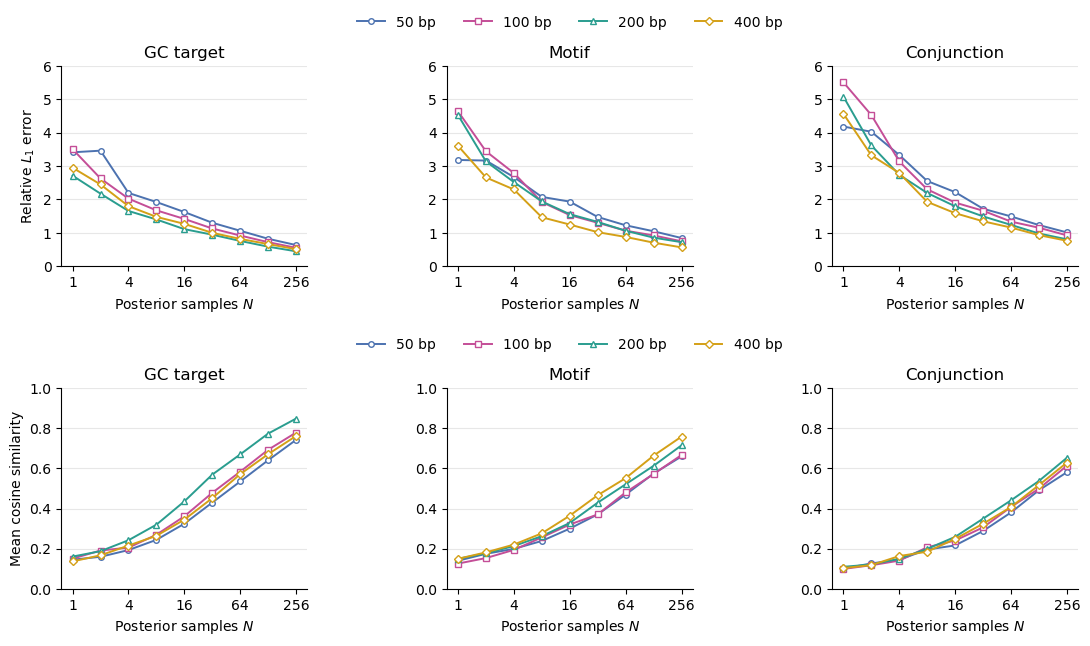

In [7]:
colors = {50: "#4c72b0", 100: "#c44e97", 200: "#2a9d8f", 400: "#d4a017"}
markers = {50: "o", 100: "s", 200: "^", 400: "D"}
titles = {"gc": "GC target", "motif": "Motif", "conjunction": "Conjunction"}
fig, axes = plt.subplots(2, 3, figsize=(11, 6.6))
for row, (metric, ylab, ylim) in enumerate([("rel_l1", r"Relative $L_1$ error", (0, 6)), ("cosine", "Mean cosine similarity", (0, 1))]):
    for col, r in enumerate(REWARDS):
        ax = axes[row, col]
        for L in LENGTHS:
            d = agg[(agg.reward == r) & (agg.length == L)].sort_values("mc")
            ax.plot(d.mc, d[metric], marker=markers[L], ms=4, mfc="white", lw=1.4, color=colors[L], label=f"{L} bp")
        ax.set_xscale("log", base=2); ax.set_xticks([1, 4, 16, 64, 256], ["1", "4", "16", "64", "256"])
        ax.set_ylim(*ylim); ax.grid(axis="y", alpha=0.3); ax.set_title(titles[r])
        ax.spines[["top", "right"]].set_visible(False)
        ax.set_xlabel("Posterior samples $N$")
        if col == 0:
            ax.set_ylabel(ylab)
    axes[row, 1].legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.12), frameon=False)
fig.tight_layout()
savefig(fig, "dna_fig5_scale_free_mc.png")
plt.show()

### Fig 5 / Tables 14–15 rerun with real dMFM gradients (authors' decision 2026-09-29)

The published panels above are GLASS-N vs GLASS-2048 (see the correction at the top of this section). The rerun
replaces the finite-N estimator with the **dMFM** posterior sampler — one composed flow-map step of the diagonal
students that Tables 13 and 17 use (`student = "diag1step"`; the 4-step Table 18 students are included as
`"dmfm4_1step"` for comparison) — against the same GLASS-2048 reference, the same 32 states, 8 pools, and the same
unmodified `rescore_gradient_pairs_scale_free` aggregation (`--bootstrap 10000 --seed 20260802`).

**What the rerun can and cannot measure.** The reference is GLASS-2048, which is itself a finite-MC estimate, so
the measured error is dominated by the *reference's own* Monte Carlo noise rather than by the estimator under test.
The published data show this on their own: over a 256-fold increase in N the published GLASS-vs-GLASS relative ℓ1
falls only ≈ 3.7× (pure 1/√N would give 16×) and is still ≈ 0.77 at N = 256, so most of the flattening already
visible in the published figure is reference noise. Consequently this experiment answers "does swapping GLASS for
dMFM at finite N degrade the gradient estimate?" but it does **not** measure the dMFM approximation error; that
would need a reference converged in N (a much larger reference, or common random numbers across the two samplers).
The paper makes the same point at l. 1727.

A **preliminary** controlled run (L = 50, motif, 4 of the 32 states, the published GLASS cells recomputed on those
same 4 states so the comparison is like-for-like) gives the answer *no, not materially*: dMFM tracks GLASS within a
ratio of 0.85–1.15 on relative ℓ1 and within ±0.06 on cosine at matched N, and it keeps decaying to N = 256
(4.3× from N = 1, against GLASS's 3.7×) with no floor visible in the measured range and no systematic penalty.
An earlier expectation that the dMFM curves would flatten at a nonzero floor well above the published y-limit was
**retracted** by the agent running it once these data arrived; the plot below therefore keeps the published axes.
Caveats on those preliminary numbers: 4 of 32 states, motif only, L = 50 only, and the dMFM side computed in fp32
on CPU against the TF32-GPU reference (a ≤ 1.9 % precision gap against 10–15 % ratio effects); they are written up,
with the retraction reasoning, in `results/dna/scale_free_mc/dmfm/preliminary/README.md`. The dotted curves are the
published GLASS-only numbers and are still *not* the same quantity as the solid ones.

In the completed runs both columns are the **same 32 conditioning states** (both sides build them with the same
unmodified `make_probe_states` from seed 20260726 + 1,000,000 + L, checked in
`results/dna/scale_free_mc/dmfm/protocol_check.json`, and a reward is only assembled once its probe ranges tile
[0, 32) and agree on a sha256 of the state tensor). The cell below asserts that from the `state_matched` /
`dmfm_n_states` columns rather than assuming it, and says so in the ratio table's caption: with matched states both
the decay factor *and* the absolute level at N = 256 are comparable, and a dMFM level close to GLASS's there is the
clearest statement that the residual is the reference's own Monte Carlo noise for both samplers.

The `compare()` cells above stay pointed at the published GLASS aggregation on purpose: they check that
`results/dna/scale_free_mc/{gc,motif,conjunction}/` still reproduces the printed PDF. The dMFM numbers are a new
result and are shown separately. Files (written by `bash scripts/dna/scalefree/collect.sh`; see
`docs/provenance/dna/scalefree.md` and `results/dna/scale_free_mc/dmfm/PROVENANCE.md`):
`results/dna/scale_free_mc/dmfm/tables14_15_cells.csv`, `.../summary.json`, and per-student/reward copies of the
same per-state and all-lengths CSVs as the published run.

The §3.3 sentence quoted above ("at N = 8, relative errors are 1.40–2.55 and cosine similarities are 0.18–0.32") is a statement about the **GLASS-only** measurement and stays attributed to it; the dMFM ranges are a separate statement, and the "no systematic deterioration from 50 to 400 bp" claim has to be re-checked per reward for the dMFM estimator, where a length trend can come from how well each length's student was distilled (the L = 400 checkpoint is a `diagonly_finetune` at epoch 33 against epoch 95 at L = 50) rather than from Monte Carlo variance. The 4-step students (`student = "dmfm4_1step"`) land later and are shown as an optional extra table, not as a Fig 5 panel.

In [8]:
# Fig 5 / Tables 14-15 with real dMFM finite-N gradients. Executes either way: until the rerun's
# files land (Slurm 49279175_[0-11%4], collected by bash scripts/dna/scalefree/collect.sh) it says so.
SFD = RESULTS / "dna" / "scale_free_mc" / "dmfm"
CELLS_CSV = SFD / "tables14_15_cells.csv"
if not CELLS_CSV.exists():
    print("Fig 5 / Tables 14-15 with dMFM gradients: PENDING (no files yet).")
    print("  runs      : Slurm 49279175_[0-11%4] (diagonal students, the Fig 5 panel) and")
    print("              49281005_[0-11%4] (4-step students, --dependency=afterany:49279175);")
    print("              49298891 (gpu_requeue) and 49297229 (serial_requeue) are alternative routes")
    print("              to the same cells, whichever partition frees up first")
    print("  collect   : bash scripts/dna/scalefree/collect.sh   (CPU, seconds), or the same with")
    print("              OUTPUT_ROOT=outputs/dna/scale_free_mc_dmfm_cpu for the CPU route's parts;")
    print("              then re-execute this notebook -- nothing else is needed")
    print("  expected  : results/dna/scale_free_mc/dmfm/tables14_15_cells.csv (+ summary.json, per-state CSVs)")
    print("  When present, this cell tabulates dMFM vs published-GLASS relative L1 / cosine per (reward, L, N)")
    print("  and redraws Fig 5 with the dMFM curves solid and the published GLASS curves dotted.")
    if SFD.exists():
        print("  present in", SFD.name + ":", sorted(p.name for p in SFD.iterdir()))
else:
    new = pd.read_csv(CELLS_CSV)
    meta = json.loads((SFD / "summary.json").read_text()) if (SFD / "summary.json").exists() else {}
    print("students:", sorted(new.student.unique()), "| rewards:", sorted(new.reward.unique()),
          "| lengths:", sorted(new.length.unique()), "| N:", sorted(new.mc.unique()))
    if meta.get("incomplete"):
        print("INCOMPLETE shards (their rows are absent above):", meta["incomplete"])
    d1 = new[new.student == "diag1step"]

    # Is the dMFM side aggregated over the same conditioning states as the published column? Both runs build
    # the states with the same unmodified make_probe_states from seed 20260726 + 1,000,000 + L (checked
    # empirically in results/dna/scale_free_mc/dmfm/protocol_check.json), and merge_parts refuses to assemble
    # a reward until the probe ranges tile [0, 32) and agree on a sha256 of the state tensor, so a completed
    # row is all 32 states on both sides. Asserted here rather than assumed, because a partial slice (e.g. a
    # 4-state preview against the published 32) would make the ratio table below compare different state sets.
    STATE_MATCHED = bool(d1["state_matched"].all()) if "state_matched" in d1.columns else None
    if "state_matched" in d1.columns:
        print("states: dMFM", sorted(d1.dmfm_n_states.unique()), "x", sorted(d1.dmfm_n_repeats.unique()), "pools;",
              "published", sorted(d1.published_glass_n_states.unique()),
              "-> state_matched:", STATE_MATCHED if STATE_MATCHED else f"NO for {int((~d1.state_matched).sum())} rows")
    else:
        print("states: this CSV predates the dmfm_n_states / state_matched columns; treating the published column "
              "as the 32-state aggregation")

    # Table 14 subset (N in {8, 128}) as "dMFM  vs  published GLASS", then the full Table 15 grid.
    # f2 tolerates a missing published cell (the collector may write null) instead of printing "nan".
    f2 = lambda s: s.map(lambda v: "-" if pd.isna(v) else f"{v:.2f}")
    t14 = d1[d1.in_table14] if "in_table14" in d1.columns else d1[d1.mc.isin([8, 128])]
    if len(t14):
        display(t14.assign(cell=lambda x: f2(x.dmfm_relative_l1) + " / " + f2(x.dmfm_cosine)
                           + "   (published GLASS " + f2(x.published_glass_relative_l1) + " / "
                           + f2(x.published_glass_cosine) + ")")
                   .pivot_table(index=["reward", "mc"], columns="length", values="cell", aggfunc="first")
                   .reindex(REWARDS, level=0))
    display(d1.assign(cell=lambda x: f2(x.dmfm_relative_l1) + " / " + f2(x.dmfm_cosine))
              .pivot_table(index=["reward", "mc"], columns="length", values="cell", aggfunc="first")
              .reindex(REWARDS, level=0))
    d4 = new[new.student == "dmfm4_1step"]          # optional extra: the 4-step (Table 18) students
    if len(d4):
        print("\nExtra (not Fig 5): the 4-step students, one composed flow-map step -- relative L1 / cosine")
        display(d4.assign(cell=lambda x: f2(x.dmfm_relative_l1) + " / " + f2(x.dmfm_cosine))
                  .pivot_table(index=["reward", "mc"], columns="length", values="cell", aggfunc="first")
                  .reindex(REWARDS, level=0))
    else:
        print("\n(no dmfm4_1step rows yet: those shards reuse the diagonal run's GLASS-2048 reference gradients)")

    # Does the dMFM error keep decaying with N? Ratio of the N=256 to the N=8 relative L1, dMFM vs published.
    # The null result is a dMFM ratio close to the published GLASS ratio (~0.3-0.4, i.e. a ~3x decay over 32x more
    # samples -- far from the 1/sqrt(N) 5.7x, because the GLASS-2048 reference is itself noisy). A dMFM ratio near
    # 1 would be the floor that an earlier prediction expected and the preliminary data did not show.
    ratio = []
    for r in REWARDS:
        for L in LENGTHS:
            g = d1[(d1.reward == r) & (d1.length == L)].set_index("mc")
            if {8, 256} <= set(g.index) and not g.loc[[8, 256], "published_glass_relative_l1"].isna().any():
                ratio.append({"reward": r, "length": L,
                              "dMFM relL1 N=8 -> N=256": f"{g.loc[8, 'dmfm_relative_l1']:.2f} -> {g.loc[256, 'dmfm_relative_l1']:.2f}",
                              "dMFM decay": round(float(g.loc[256, "dmfm_relative_l1"] / g.loc[8, "dmfm_relative_l1"]), 3),
                              "GLASS decay": round(float(g.loc[256, "published_glass_relative_l1"]
                                                         / g.loc[8, "published_glass_relative_l1"]), 3),
                              "dMFM relL1 at N=256": round(float(g.loc[256, "dmfm_relative_l1"]), 3),
                              "GLASS relL1 at N=256": round(float(g.loc[256, "published_glass_relative_l1"]), 3)})
    if ratio:
        ratio = pd.DataFrame(ratio)
        ratio["dMFM / GLASS at N=256"] = (ratio["dMFM relL1 at N=256"] / ratio["GLASS relL1 at N=256"]).round(3)
        _label = ("state-matched: both columns are the same 32 conditioning states" if STATE_MATCHED
                  else "published column is the 32-state aggregation and THE STATE SETS DIFFER -- decay factors are "
                       "still meaningful per column, absolute levels are not comparable" if STATE_MATCHED is False
                       else "published column assumed to be the 32-state aggregation (no state_matched column)")
        print(f"\nRatios below ({_label}). The published GLASS column is the yardstick in two ways: its decay"
              "\nfactor (limited by the GLASS-2048 reference's own noise, not by 1/sqrt(N)) and its absolute level"
              "\nat N=256. A dMFM decay close to GLASS's means no extra dMFM floor; a dMFM level close to GLASS's"
              "\nat N=256 means the residual is the reference's own Monte Carlo noise for both samplers, which is"
              "\nwhat l. 1727 concedes. Retraction and preliminary numbers: "
              "results/dna/scale_free_mc/dmfm/preliminary/README.md")
        display(ratio)

    colors = {50: "#4c72b0", 100: "#c44e97", 200: "#2a9d8f", 400: "#d4a017"}
    markers = {50: "o", 100: "s", 200: "^", 400: "D"}
    titles = {"gc": "GC target", "motif": "Motif", "conjunction": "Conjunction"}
    fig, axes = plt.subplots(2, 3, figsize=(11, 6.6))
    # published axes: the preliminary data sit inside (0, 6), so there is no reason to rescale or take a log
    for row, (metric, ylab, ylim) in enumerate([("dmfm_relative_l1", r"Relative $L_1$ error", (0, 6)),
                                                ("dmfm_cosine", "Mean cosine similarity", (0, 1))]):
        for col, r in enumerate(REWARDS):
            ax = axes[row, col]
            for L in LENGTHS:
                dd = d1[(d1.reward == r) & (d1.length == L)].sort_values("mc")
                if len(dd):
                    ax.plot(dd.mc, dd[metric], marker=markers[L], ms=4, mfc="white", lw=1.4, color=colors[L],
                            label=f"{L} bp (dMFM)")
                gg = agg[(agg.reward == r) & (agg.length == L)].sort_values("mc")
                ax.plot(gg.mc, gg["rel_l1" if row == 0 else "cosine"], lw=0.9, ls=":", color=colors[L], alpha=0.55,
                        label=f"{L} bp (GLASS-only, as published)" if row == 0 and col == 0 else None)
            ax.set_xscale("log", base=2)
            ax.set_xticks([1, 4, 16, 64, 256], ["1", "4", "16", "64", "256"])
            if ylim:
                ax.set_ylim(*ylim)
            ax.grid(axis="y", alpha=0.3)
            ax.set_title(titles[r])
            ax.spines[["top", "right"]].set_visible(False)
            ax.set_xlabel("Posterior samples $N$")
            if col == 0:
                ax.set_ylabel(ylab)
    axes[0, 1].legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.12), frameon=False, fontsize=7)
    fig.tight_layout()
    savefig(fig, "dna_fig5_scale_free_mc_dmfm.png")
    plt.show()
    print("solid = dMFM finite-N gradients (one composed flow-map step of the diagonal students);\n"
          "dotted = the published GLASS-N vs GLASS-2048 curves, a different quantity. Axes as published:\n"
          "the error measured here is dominated by the GLASS-2048 reference's own Monte Carlo noise, so\n"
          "neither curve isolates the dMFM approximation error (see the markdown above).")

Fig 5 / Tables 14-15 with dMFM gradients: PENDING (no files yet).
  runs      : Slurm 49279175_[0-11%4] (diagonal students, the Fig 5 panel) and
              49281005_[0-11%4] (4-step students, --dependency=afterany:49279175);
              49298891 (gpu_requeue) and 49297229 (serial_requeue) are alternative routes
              to the same cells, whichever partition frees up first
  collect   : bash scripts/dna/scalefree/collect.sh   (CPU, seconds), or the same with
              OUTPUT_ROOT=outputs/dna/scale_free_mc_dmfm_cpu for the CPU route's parts;
              then re-execute this notebook -- nothing else is needed
  expected  : results/dna/scale_free_mc/dmfm/tables14_15_cells.csv (+ summary.json, per-state CSVs)
  When present, this cell tabulates dMFM vs published-GLASS relative L1 / cosine per (reward, L, N)
  and redraws Fig 5 with the dMFM curves solid and the published GLASS curves dotted.
  present in dmfm: ['PROVENANCE.md', 'precision_bound.json', 'preliminary', 'protoc

## Table 17 — posterior diversity (dMFM one-map vs GLASS-100)
32 held-out test sources per length, 16 matched terminal noises per (source, t); dMFM = the map-selected checkpoints
(one direct flow-map step), GLASS = 100 Euler steps. Entry = mean over the 32 conditions of the normalized pairwise
Hamming distance among the 16 decoded futures (`posterior_condition_metrics.csv`).

In [9]:
pc = load_csv("dna/posterior_diversity/posterior_condition_metrics.csv")
m17 = pc.groupby(["length", "t", "method"]).pairwise_hamming_frac.mean().unstack("method")
rows = []
for tt, byL in {k: v for k, v in P["table17_posterior_diversity"].items() if not k.startswith("_")}.items():
    for L, (pd_, pg) in byL.items():
        rows += [dict(item=f"t={tt} L{L} dMFM", paper=pd_, ours=m17.loc[(int(L), float(tt)), "dmfm"], dec=3),
                 dict(item=f"t={tt} L{L} GLASS", paper=pg, ours=m17.loc[(int(L), float(tt)), "glass"], dec=3)]
t17 = show(cmp(rows))
print("conditions per cell:", pc.groupby(["length", "t", "method"]).size().unique(), "| run config:")
load_csv("dna/posterior_diversity/run_config.csv")

status counts: {'match': 32}
conditions per cell: [32] | run config:


,length,student_dir,student_ckpt,n_sources,n_futures,dmfm_sampler,dmfm_steps,glass_steps,times,seed
0,50,workdir/yeast_parent_a_L50_dmfm_diagonal_h192_b4,epoch=95-step=49000.ckpt,32,16,flow_map,1,100,0.0 0.25 0.5 0.75 0.9 0.99 1.0,20260730
1,100,workdir/yeast_parent_a_L100_dmfm_diagonal_h192_b4,epoch=80-step=39000.ckpt,32,16,flow_map,1,100,0.0 0.25 0.5 0.75 0.9 0.99 1.0,20260730
2,200,workdir/yeast_parent_a_L200_dmfm_diagonal_h192_b4,epoch=51-step=45000.ckpt,32,16,flow_map,1,100,0.0 0.25 0.5 0.75 0.9 0.99 1.0,20260730
3,400,workdir/yeast_parent_a_L400_dmfm_diagonly_finetune_20260726,epoch=33-step=45750-v1.ckpt,32,16,flow_map,1,100,0.0 0.25 0.5 0.75 0.9 0.99 1.0,20260730


In [10]:
m17.assign(abs_diff=lambda d: (d.dmfm - d.glass).abs()).round(4).unstack("length")

method    dmfm                           glass                         abs_diff                        
length     50      100     200     400     50      100     200     400      50      100     200     400
t                                                                                                      
0.00    0.7320  0.7372  0.7423  0.7315  0.7357  0.7377  0.7401  0.7327   0.0037  0.0005  0.0022  0.0013
0.25    0.7129  0.7110  0.7169  0.7136  0.7161  0.7142  0.7173  0.7132   0.0032  0.0032  0.0004  0.0004
0.50    0.5634  0.5516  0.5557  0.5670  0.5551  0.5630  0.5587  0.5545   0.0083  0.0113  0.0030  0.0125
0.75    0.0633  0.0561  0.0610  0.0668  0.0593  0.0596  0.0606  0.0605   0.0040  0.0035  0.0004  0.0064
0.90    0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000   0.0000  0.0000  0.0000  0.0000
0.99    0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000   0.0000  0.0000  0.0000  0.0000
1.00    0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000   0.0000  0.0000  0.0000  0.0000

At t ≥ 0.9 both samplers return the source exactly (diversity 0), as the paper notes ("diversity will collapse for
increasing t"); the largest |dMFM − GLASS| over the printed cells is shown above.

## Table 18 — raw per-coordinate gradient MAE of the 4-map dMFM vs a GLASS-128 reference
4-step students `yeast_parent_a_L*_dmfm_4step_esd_gap_upto025_corrected_20260727` (steps 15,000 / 149,000 / 34,000 /
129,000), 32 held-out states, 8 pools, nested MC prefixes, reference GLASS with 128 samples and 50-step RK4.
MAE per (state, pool, N) is stored in `gradient_mae_per_condition.csv`; the table entry is the mean over states of the
per-state mean over pools (`rescore_gradient_pairs_mae.py`).

**Known mismatch:** App. F.6 says outer time t = 0.3; every run's metadata records `t_eval = 0.5`.

In [11]:
p18 = P["table18_dmfm_vs_glass128_mae"]
rows, meta = [], []
for r in REWARDS:
    md = load_json(f"dna/dmfm_vs_glass/{r}/run_metadata.json")
    meta.append({"reward": r, "t_eval": md["args"]["t_eval"], "n_probes": md["args"]["n_probes"], "n_repeats": md["args"]["n_repeats"],
                 "reference_mc": md["args"]["reference_mc"], "reference": f"{md['args']['reference_sampler']} {md['args']['reference_glass_solver']}-{md['args']['reference_glass_steps']}",
                 "dmfm_steps": md["args"]["dmfm_steps"], "nested_pools": md["args"].get("nested_mc_pools")})
    for L in LENGTHS:
        pcnd = load_csv(f"dna/dmfm_vs_glass/{r}/L{L}/gradient_mae_per_condition.csv")
        state = pcnd.groupby(["mc", "probe"]).mae.mean().groupby("mc").mean()
        for j, mc in enumerate([1, 2, 4, 8]):
            rows.append(dict(item=f"{r} L{L} MC={mc}", paper=p18[r][str(L)][j], ours=float(state.loc[mc]), dec=4))
t18 = show(cmp(rows))
pd.DataFrame(meta)

status counts: {'match': 46, 'MISMATCH': 2}


,reward,t_eval,n_probes,n_repeats,reference_mc,reference,dmfm_steps,nested_pools
0,gc,0.5,32,8,128,glass rk4-50,4,True
1,motif,0.5,32,8,128,glass rk4-50,4,True
2,conjunction,0.5,32,8,128,glass rk4-50,4,True


**The two Table 18 MISMATCHes are last-digit rounding artifacts in the paper, not data differences.** gc L100 MC=2 is
0.1233465 (paper 0.1234) and motif L50 MC=1 is 0.2187464 (paper 0.2188). Rounding first to 5 decimals and then to 4
(0.12335 → 0.1234, 0.21875 → 0.2188) gives the printed values; single rounding gives 0.1233 and 0.2187. They are left
as MISMATCH (the stored `gradient_mae_summary_all_lengths.csv` has the same means); the check below shows it.

In [12]:
from decimal import Decimal, ROUND_HALF_UP
bad = t18[t18.status != "match"].copy()
bad["round_4"] = [f"{v:.4f}" for v in bad.ours]
bad["round_5_then_4"] = [str(Decimal(f"{v:.5f}").quantize(Decimal("0.0001"), ROUND_HALF_UP)) for v in bad.ours]
bad

,item,paper,ours,status,tol,tol_src,note,round_4,round_5_then_4
5,gc L100 MC=2,0.1234,0.123347,MISMATCH,0.00005,atol,,0.1233,0.1234
16,motif L50 MC=1,0.2188,0.218746,MISMATCH,0.00005,atol,,0.2187,0.2188


Two entries differ from the paper in the last printed digit: GC L = 100, MC = 2 (recomputed 0.1233465, paper 0.1234) and
motif L = 50, MC = 1 (0.2187464 vs 0.2188). Both equal the stored summaries of the original run, and both paper values
are what one gets by rounding to 5 decimals first (0.12335, 0.21875) and then to 4 (double rounding); the table was
copied from `docs/rebuttal_gradient_acc.md`, which has the same values and, incidentally, states t = 0.5. Left as
MISMATCH (|Δ| ≤ 1e-4); the underlying data are the same run.

In [13]:
show(cmp([dict(item=f"{m['reward']} outer time t", paper=p18["text_t"], ours=m["t_eval"], dec=1, note="KNOWN: text says 0.3, runs used 0.5") for m in meta]
         + [dict(item=f"{m['reward']} held-out states", paper=p18["text_n_states"], ours=m["n_probes"], atol=0) for m in meta]
         + [dict(item=f"{m['reward']} noise pools per state", paper=p18["text_n_pools"], ours=m["n_repeats"], atol=0) for m in meta]
         + [dict(item=f"{m['reward']} GLASS reference MC", paper=128, ours=m["reference_mc"], atol=0, note=p18["text_glass_reference"]) for m in meta]
         + [dict(item=f"{m['reward']} GLASS reference RK4 steps", paper=50, ours=float(m["reference"].split("-")[-1]) if m["reference"].split(" ")[-1].startswith("rk4") else None,
                 atol=0, note=m["reference"]) for m in meta]))

status counts: {'match': 12, 'MISMATCH': 3}


,item,paper,ours,status,tol,tol_src,note
0,gc outer time t,0.3,0.5,MISMATCH,0.05,atol,"KNOWN: text says 0.3, runs used 0.5"
1,motif outer time t,0.3,0.5,MISMATCH,0.05,atol,"KNOWN: text says 0.3, runs used 0.5"
2,conjunction outer time t,0.3,0.5,MISMATCH,0.05,atol,"KNOWN: text says 0.3, runs used 0.5"
3,gc held-out states,32.0,32.0,match,0.00,atol,
4,motif held-out states,32.0,32.0,match,0.00,atol,
5,conjunction held-out states,32.0,32.0,match,0.00,atol,
6,gc noise pools per state,8.0,8.0,match,0.00,atol,
7,motif noise pools per state,8.0,8.0,match,0.00,atol,
8,conjunction noise pools per state,8.0,8.0,match,0.00,atol,
9,gc GLASS reference MC,128.0,128.0,match,0.00,atol,"GLASS-128, 50-step RK4"


## RERUN = True — rerun on one GPU at small n

Every cell below reruns a real experiment of this section through the ported package `src/dmfm`
(the same `dmfm.experiments.*` entry points that `scripts/dna/*.sbatch` call for the full-size
runs), at a small number of samples/states, and prints the small-n result next to the stored
full-size number. They need a CUDA GPU and `source scripts/env.sh`; outputs go to
`outputs/dna/notebook_rerun/` (gitignored). Turn them on without editing the notebook with

```bash
DNA_RERUN=1 jupyter nbconvert --to notebook --execute --ExecutePreprocessor.kernel_name=multimfm \
    --output-dir <somewhere outside the repo> <this notebook>
```

(see `scripts` in the DNA provenance notes, or `python notebooks/_dna_helpers.py rerun <nb>`).
With `RERUN = False` each cell prints one line saying what it would rerun.

**Guided sampling is not bit-reproducible.** The value gradient is accumulated through a
nondeterministic CUDA backward and cuBLAS/cuDNN kernels depend on batch shape and GPU model, so
guided sequences and their scores differ between runs and from the stored runs; they agree
statistically. The *unguided* branch takes no gradient and is deterministic — it must match the
stored sequences exactly, and the cells below check that.

In [14]:
# Tables 14-15 / Fig 5 RERUN: finite-MC GLASS value-gradient accuracy on the base DFM
# (dmfm.experiments.ablate_glass_gradient_mc, the flags of scripts/dna/fig5_tables14_15_gradient_mc.sbatch)
# followed by the scale-free rescore (dmfm.experiments.rescore_gradient_pairs_scale_free).
if RERUN:
    dev = require_gpu()
    REWARD_R, L_R, MCS = "motif", 50, [1, 2, 4, 8, 16]
    rerun_banner(f"Tables 14-15 / Fig 5 - finite-MC GLASS gradient accuracy ({REWARD_R}, L={L_R})",
                 small=f"2 of the 32 probe states x 2 of the 8 noise pools, N in {MCS}, GLASS-2048 reference",
                 stored="32 states x 8 pools, N in {1..256}, four lengths, three rewards (job 35258314)",
                 not_bit_exact=False)
    print("Probe states, the reference noise pool and every estimate pool are seeded per\n"
          "(probe, N, pool), so states 0-1 / pools 0-1 are the same conditions as in the full-size run\n"
          "(the probe states are integrated through the base flow with all n_probes in one batch, so a\n"
          "batch of 2 instead of 32 reassociates the matmuls: expect ~1e-5 relative, not bit equality),\n"
          "and the 1,024-sample calibration is unchanged, so score_center / score_std reproduce.\n"
          "The pooled metrics are averages over states, so with 2 states they carry real sampling error:\n"
          "the band below is the distribution of a 2-state estimate resampled from the stored 32 states.\n")
    d = rerun_dir("gradient_mc", REWARD_R)
    run_experiment("ablate_glass_gradient_mc", [
        "--output_dir", d, "--reward", REWARD_R, "--lengths", L_R, "--seed", 20260726,
        "--t_eval", 0.50, "--nfe_probe", 32, "--nfe_calibration", 64, "--calibration_samples", 1024,
        "--sample_batch_size", 32, "--nfe_value", 8, "--glass_end_time", 1.0,
        "--n_probes", 2, "--n_repeats", 2, "--reference_mc", 2048, "--mc_values", *MCS,
        "--mc_chunk", 16, "--z_target", 1.0, "--reward_beta", 1.0, "--reward_scale", 1.0,
        "--thresholds", 0.05, 0.10, 0.20, "--bootstrap", 200])
    run_experiment("rescore_gradient_pairs_scale_free", ["--input-dir", d, "--bootstrap", 200, "--seed", 20260802])

    new = pd.read_csv(d / "gradient_scale_free_summary_all_lengths.csv").set_index("mc")
    stored = agg[(agg.reward == REWARD_R) & (agg.length == L_R)].set_index("mc")
    ss = sf[(sf.reward == REWARD_R) & (sf.length == L_R)]
    # What can and cannot be checked at 2 states x 2 pools. The *metrics* cannot: at N = 1-2 a single
    # MC gradient estimate is so noisy that a per-state mean over 2 pools is not an estimate of the
    # stored mean over 8 pools (a 1-pool CPU rescore of dna-core's smoke run gave per-state relative-L1
    # ratios of 0.22-0.89 and a cosine of 0.003 where the stored 8-pool mean is 0.200). So the pooled
    # numbers are shown side by side and only checked for the right order of magnitude and the right
    # trend in N; what *is* checked exactly is everything deterministic: the calibration that sets the
    # reward, the evaluation time, and (below) the per-state agreement of the reference gradients.
    side = pd.DataFrame([{"N": mc,
                          "relative L1 (this run)": round(float(new.loc[mc, "global_relative_l1"]), 3),
                          "relative L1 (stored, 32x8)": round(float(stored.loc[mc, "rel_l1"]), 3),
                          "cosine (this run)": round(float(new.loc[mc, "mean_cosine"]), 3),
                          "cosine (stored, 32x8)": round(float(stored.loc[mc, "cosine"]), 3)} for mc in MCS])
    display(side)
    l1_new = np.array([float(new.loc[mc, "global_relative_l1"]) for mc in MCS])
    cos_new = np.array([float(new.loc[mc, "mean_cosine"]) for mc in MCS])
    l1_old = np.array([float(stored.loc[mc, "rel_l1"]) for mc in MCS])
    cos_old = np.array([float(stored.loc[mc, "cosine"]) for mc in MCS])
    checks = [
        dict(item="relative L1 falls as N grows (Spearman with N)", paper=-1.0, atol=0.35,
             ours=float(pd.Series(l1_new).corr(pd.Series(MCS, dtype=float), method="spearman")),
             note=f"stored: {pd.Series(l1_old).corr(pd.Series(MCS, dtype=float), method='spearman'):+.2f}"),
        dict(item="cosine rises as N grows (Spearman with N)", paper=1.0, atol=0.35,
             ours=float(pd.Series(cos_new).corr(pd.Series(MCS, dtype=float), method="spearman")),
             note=f"stored: {pd.Series(cos_old).corr(pd.Series(MCS, dtype=float), method='spearman'):+.2f}; "
                  "the published trend is a mean over 32 states x 8 pools -- with 2 states x 2 pools a single "
                  "unlucky pool can invert one step, so a MISMATCH here is sampling noise, not a port bug: the "
                  "per-state reference-gradient norms and the factor bounds below are the checks that must hold"),
        dict(item="relative L1 within a factor 4 of the stored value at every N (1 = yes)", paper=1.0, atol=0,
             ours=float(bool(np.all((l1_new / l1_old > 0.25) & (l1_new / l1_old < 4.0)))),
             note=f"ratios {np.round(l1_new / l1_old, 2).tolist()}"),
        dict(item="cosine within a factor 3 of the stored value at every N (1 = yes)", paper=1.0, atol=0,
             ours=float(bool(np.all((cos_new / cos_old > 1 / 3) & (cos_new / cos_old < 3.0)))),
             note=f"ratios {np.round(cos_new / cos_old, 2).tolist()}"),
    ]
    # The reference gradient IS reproducible (a 2,048-sample estimate), and its per-state L1 norm is
    # stored for every state in scale_free_per_state_sums.csv, so states 0-1 can be checked directly.
    import torch
    pairs = torch.load(d / f"L{L_R}" / "gradient_pairs.pt", map_location="cpu", weights_only=False)
    ref_l1_new = pairs["reference_gradients"].abs().sum(dim=(-1, -2)).numpy()
    ref_l1_old = ss[ss.mc == MCS[0]].sort_values("state").ref_l1.to_numpy()
    checks += [dict(item=f"state {s}: L1 norm of the GLASS-2048 reference gradient",
                    paper=float(ref_l1_old[s]), ours=float(ref_l1_new[s]), rtol=0.02,
                    note="reproducible: 2,048 posterior samples, seeded per state; tolerance 2% relative")
               for s in range(len(ref_l1_new))]
    display(stored_vs_small(checks))
    md = json.loads((d / f"L{L_R}" / "metadata.json").read_text())
    ref_md = {m["length"]: m for m in load_json(f"dna/scale_free_mc/{REWARD_R}/run_metadata.json")["per_length"]}[L_R]
    display(stored_vs_small([
        dict(item="reward score_center (motif 90th percentile of the calibration)", paper=ref_md["score_center"],
             ours=md["score_center"], atol=1e-4, note="same calibration seed, size and NFE"),
        dict(item="reward score_std", paper=ref_md["score_std"], ours=md["score_std"], atol=1e-4),
        dict(item="t_eval", paper=ref_md["t_eval"], ours=md["t_eval"], atol=0),
        dict(item="glass_end_time", paper=ref_md.get("glass_end_time"), ours=md["glass_end_time"], atol=0,
             note="n/a: the flag did not exist when the original run was made (assumed 1.0; see the wrapper)"),
    ]))
    print("\nFull size (three rewards x four lengths, ~12 h each):\n"
          "  REWARD=<gc|motif|conjunction> sbatch scripts/dna/fig5_tables14_15_gradient_mc.sbatch\n"
          "  bash scripts/dna/fig5_tables14_15_rescore.sh <run dirs>")
else:
    print("RERUN = False: Tables 14-15 and Fig 5 are re-aggregated above from")
    print("results/dna/scale_free_mc/scale_free_per_state_sums.csv (float64 sums of the stored gradients).")
    print("RERUN = True reruns 2 states x 2 pools at L=50 with dmfm.experiments.ablate_glass_gradient_mc")
    print("and rescores them with rescore_gradient_pairs_scale_free.")

RERUN = False: Tables 14-15 and Fig 5 are re-aggregated above from
results/dna/scale_free_mc/scale_free_per_state_sums.csv (float64 sums of the stored gradients).
RERUN = True reruns 2 states x 2 pools at L=50 with dmfm.experiments.ablate_glass_gradient_mc
and rescores them with rescore_gradient_pairs_scale_free.


In [15]:
# Table 17 RERUN: conditional posterior diversity, dMFM one-step flow map vs GLASS-100
# (dmfm.experiments.eval_posterior_diversity = scripts/dna/table17_posterior_diversity.sbatch),
# 4 of the 32 held-out sources at L=50. Reward-free, no gradients: this one is reproducible.
if RERUN:
    dev = require_gpu()
    NS, NF = 4, 16
    rerun_banner("Table 17 - posterior diversity, dMFM one map vs GLASS-100 (L=50)",
                 small=f"{NS} of the 32 held-out sources x {NF} matched futures, all seven times",
                 stored="32 sources x 16 futures, L=50..400 (job 35378081)", not_bit_exact=False)
    print("Sources are randperm(seed+L)[:n_sources] and the conditioning/terminal noise is drawn\n"
          "row-major from one seed per (length, time index), so these 4 sources and their 16 futures\n"
          "ARE the stored run's first 4 conditions: the per-condition metrics must reproduce exactly\n"
          "(all seven times are passed so the time index, which seeds the noise, still lines up).\n")
    d = rerun_dir("posterior_diversity")
    run_experiment("eval_posterior_diversity", [
        "--lengths", 50, "--times", 0.0, 0.25, 0.5, 0.75, 0.9, 0.99, 1.0,
        "--n_sources", NS, "--n_futures", NF, "--source_batch", 4,
        "--dmfm_steps", 1, "--dmfm_sampler", "flow_map", "--glass_steps", 100,
        "--bootstrap", 200, "--seed", 20260730, "--out_dir", d])
    new = pd.read_csv(d / "posterior_condition_metrics.csv")
    keys = ["length", "t", "method", "source_id"]
    both = new.merge(pc, on=keys, suffixes=("_rerun", "_stored"))
    print(f"matched conditions: {len(both)} of {len(new)} rerun rows "
          f"(source_ids {sorted(new.source_id.unique().tolist())})")
    # The metrics are discrete functions of argmax-decoded futures, so a float32 near-tie that flips on a
    # different device or cuBLAS version moves them slightly: one flipped base among the 16 x 50 decoded
    # positions shifts the pairwise fraction by ~0.0025. A CPU rerun of source 7693 (this same command with
    # n_sources=1) reproduced t = 0, 0.75, 0.9, 0.99 and 1.0 exactly and differed by at most 0.0155 at
    # t = 0.25 / 0.5, so the check below allows a few flipped bases, and the number of bit-identical
    # conditions is reported next to it instead of being asserted.
    METRICS17 = ["pairwise_hamming_frac", "nearest_generated_frac", "source_hamming_frac", "exact_unique_frac"]
    n_exact = int(sum(all(r[f"{m}_rerun"] == r[f"{m}_stored"] for m in METRICS17) for _, r in both.iterrows()))
    print(f"conditions whose four metrics are bit-identical to the stored run: {n_exact}/{len(both)}")
    display(stored_vs_small([
        dict(item=f"max |{m}: rerun - stored| over the matched conditions", paper=0.0, atol=0.05,
             ours=float((both[f"{m}_rerun"] - both[f"{m}_stored"]).abs().max()),
             note="same sources, same noise; only argmax near-ties can differ")
        for m in METRICS17]))

    # Table 17 cells: the 4-source mean against the stored 32-source mean, with the null of a
    # 4-source subsample of the stored 32 as the band.
    m_new = new.groupby(["t", "method"]).pairwise_hamming_frac.mean()
    rng = np.random.default_rng(0)
    rows = []
    for tt in sorted(new.t.unique()):
        for method in ["dmfm", "glass"]:
            v = pc[(pc.length == 50) & (pc.t == tt) & (pc.method == method)].pairwise_hamming_frac.to_numpy()
            null = np.quantile(v[rng.integers(0, len(v), size=(4000, NS))].mean(1), [0.025, 0.975])
            rows.append(dict(item=f"t={tt:g} {method}", stored=round(float(v.mean()), 4), ci=tuple(null.round(4)),
                             ours=round(float(m_new.loc[(tt, method)]), 4),
                             note=f"band = {NS}-source subsamples of the stored 32"))
    display(agree_ci(rows))
    print("\nFull size (all four lengths, ~4 h): sbatch scripts/dna/table17_posterior_diversity.sbatch")
else:
    print("RERUN = False: Table 17 is rebuilt above from results/dna/posterior_diversity/posterior_condition_metrics.csv.")
    print("RERUN = True reruns 4 of the 32 L=50 sources with dmfm.experiments.eval_posterior_diversity;")
    print("their per-condition metrics must equal the stored ones exactly.")

RERUN = False: Table 17 is rebuilt above from results/dna/posterior_diversity/posterior_condition_metrics.csv.
RERUN = True reruns 4 of the 32 L=50 sources with dmfm.experiments.eval_posterior_diversity;
their per-condition metrics must equal the stored ones exactly.


In [16]:
# Table 18 RERUN: raw per-coordinate value-gradient MAE of the 4-step dMFM against a GLASS-128
# (RK4-50) reference (dmfm.experiments.ablate_dmfm_one_step_gradient_mc, the flags of
# scripts/dna/table18_dmfm4_gradient_mc.sbatch), then the MAE rescore, at 2 states x 2 pools.
if RERUN:
    from dmfm import paths as dpaths

    dev = require_gpu()
    REWARD_18, L18, MC18 = "gc", 50, [1, 2, 4, 8]
    rerun_banner(f"Table 18 - 4-step dMFM gradient MAE vs GLASS-128 ({REWARD_18}, L={L18})",
                 small=f"2 of the 32 held-out states x 2 of the 8 nested noise pools, MC in {MC18}",
                 stored="32 states x 8 pools, 3 rewards x 4 lengths (job array 35642548)",
                 not_bit_exact=False)
    print("--nested_mc_pools draws one pool of max(MC)=8 per (state, pool) and uses its prefixes, and\n"
          "max(MC) is unchanged, so states 0-1 / pools 0-1 are the stored run's first conditions and\n"
          "their per-condition MAEs must reproduce (float32 / GPU nondeterminism aside).\n")
    d = rerun_dir("dmfm4_glass128_mae", REWARD_18)
    run_experiment("ablate_dmfm_one_step_gradient_mc", [
        "--output_dir", d, "--lengths", L18, "--dmfm_ckpt", f"{L18}={dpaths.dmfm4_ckpt(L18)}",
        "--reward", REWARD_18, "--reward_objective", "target", "--seed", 20260802, "--t_eval", 0.50,
        "--nfe_calibration", 32, "--calibration_samples", 128, "--sample_batch_size", 16,
        "--n_probes", 2, "--n_repeats", 2, "--reference_mc", 128, "--reference_sampler", "glass",
        "--reference_glass_steps", 50, "--reference_glass_solver", "rk4", "--glass_end_time", 0.999,
        "--dmfm_sampler", "flow_map", "--dmfm_steps", 4, "--dmfm_end_time", 0.999,
        "--mc_values", *MC18, "--nested_mc_pools", "--mc_chunk", 16,
        "--z_target", 1.0, "--reward_beta", 1.0, "--reward_scale", 1.0,
        "--thresholds", 0.05, 0.10, 0.20, "--bootstrap", 200])

    # Raw per-coordinate MAE (what Table 18 prints): dmfm.experiments.rescore_gradient_pairs_mae,
    # with its original --bootstrap 10000 --seed 20260802. notebooks/_dna_helpers.rescore_gradient_mae
    # is the same computation and is kept as a fallback for older checkouts of the package.
    if has_module("dmfm.experiments.rescore_gradient_pairs_mae"):
        run_experiment("rescore_gradient_pairs_mae", ["--input-dir", d, "--bootstrap", 10000, "--seed", 20260802])
        display(pd.read_csv(d / "gradient_mae_summary_all_lengths.csv").round(5))
    else:
        print("dmfm.experiments.rescore_gradient_pairs_mae not importable; using the port in _dna_helpers.py")
        display(rescore_gradient_mae(d, bootstrap=10000).round(5))

    new_cond = pd.read_csv(d / f"L{L18}" / "gradient_mae_per_condition.csv")
    stored_cond = load_csv(f"dna/dmfm_vs_glass/{REWARD_18}/L{L18}/gradient_mae_per_condition.csv")
    both = new_cond.merge(stored_cond, on=["length", "probe", "repeat", "mc"], suffixes=("_rerun", "_stored"))
    rel = (both.mae_rerun - both.mae_stored).abs() / both.mae_stored.clip(lower=1e-12)
    display(stored_vs_small([
        dict(item=f"per-condition MAEs matched (probes 0-1, pools 0-1, MC {MC18})", paper=len(MC18) * 4,
             ours=len(both), atol=0),
        dict(item="max |MAE - stored MAE| over those conditions", paper=0.0, atol=0.05,
             ours=float((both.mae_rerun - both.mae_stored).abs().max()),
             note="loose bound, not a precision claim: the per-condition MAEs span ~1e-3 to ~5e-1"),
        dict(item="median relative difference vs the stored per-condition MAE", paper=0.0, atol=0.10,
             ours=float(rel.median())),
        dict(item="max relative difference vs the stored per-condition MAE", paper=0.0, ours=float(rel.max()), atol=0.25,
             note="both the GLASS-128 reference and the dMFM estimate are autodiff gradients through a "
                  "nondeterministic CUDA backward, so a few per cent of per-condition drift is expected; a CPU "
                  "rescore of dna-core's smoke tensors (motif, L=50, probes 0-1) gave up to 8.7% / 0.016 absolute"),
        dict(item="Spearman correlation of the rerun and the stored per-condition MAEs", paper=1.0, atol=0.05,
             ours=float(pd.Series(both.mae_rerun.to_numpy()).corr(pd.Series(both.mae_stored.to_numpy()), method="spearman")),
             note="the conditions keep their order, i.e. the same gradients are being compared"),
    ]))
    # The printed Table 18 cell is the mean over the 32 states of the per-state mean over 8 pools. The exact
    # reference for THIS rerun is the same subset of the stored run (states 0-1, pools 0-1); the 32-state value
    # is then shown with the band a 2-state estimate of it would have, which is context, not a pass/fail.
    sub = stored_cond[(stored_cond.probe < 2) & (stored_cond.repeat < 2)]
    state_new = new_cond.groupby(["mc", "probe"]).mae.mean().groupby("mc").mean()
    state_sub = sub.groupby(["mc", "probe"]).mae.mean().groupby("mc").mean()
    display(stored_vs_small([
        dict(item=f"{REWARD_18} L{L18} MC={mc}: same subset of the stored run (states 0-1, pools 0-1)", atol=5e-3,
             paper=round(float(state_sub.loc[mc]), 5), ours=round(float(state_new.loc[mc]), 5),
             note="the like-for-like comparison; the 32-state cell below differs because states 0-1 are 2 of 32, "
                  "not because the port differs")
        for mc in MC18]))
    state_stored = stored_cond.groupby(["mc", "probe"]).mae.mean()
    rng = np.random.default_rng(0)
    rows = []
    for j, mc in enumerate(MC18):
        v = state_stored.loc[mc].to_numpy()
        null = np.quantile(v[rng.integers(0, len(v), size=(4000, 2))].mean(1), [0.025, 0.975])
        rows.append(dict(item=f"{REWARD_18} L{L18} MC={mc}", stored=round(float(v.mean()), 4), ci=tuple(null.round(4)),
                         ours=round(float(state_new.loc[mc]), 4),
                         note=f"paper prints {p18[REWARD_18][str(L18)][j]}; band = 2-state subsamples of the stored 32"))
    display(agree_ci(rows))
    print("\nFull size (12 array tasks): sbatch scripts/dna/table18_dmfm4_gradient_mc.sbatch")
else:
    print("RERUN = False: Table 18 is rebuilt above from results/dna/dmfm_vs_glass/*/L*/gradient_mae_per_condition.csv.")
    print("RERUN = True reruns 2 states x 2 pools at L=50 with dmfm.experiments.ablate_dmfm_one_step_gradient_mc")
    print("and recomputes the raw MAE with dmfm.experiments.rescore_gradient_pairs_mae.")

RERUN = False: Table 18 is rebuilt above from results/dna/dmfm_vs_glass/*/L*/gradient_mae_per_condition.csv.
RERUN = True reruns 2 states x 2 pools at L=50 with dmfm.experiments.ablate_dmfm_one_step_gradient_mc
and recomputes the raw MAE with dmfm.experiments.rescore_gradient_pairs_mae.
